# Netflix Movies and TV Shows - Exploratory Data Analysis

This notebook performs EDA as per project requirements:
1. Understanding content types available in different countries
2. Analyze if Netflix has been increasingly focusing on TV rather than movies in recent years
3. Clustering similar content by matching text-based features

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

plt.style.use('ggplot')
sns.set_palette('Set2')

df = pd.read_csv('netflix_titles.csv')
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...
1,80117401,Movie,Jandino: Whatever it Takes,NaN,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...
2,70234439,TV Show,Transformers Prime,NaN,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob..."
3,80058654,TV Show,Transformers: Robots in Disguise,NaN,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...


In [14]:
df.shape
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 6234 entries, 0 to 6233
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       6234 non-null   int64
 1   type          6234 non-null   str  
 2   title         6234 non-null   str  
 3   director      4265 non-null   str  
 4   cast          5664 non-null   str  
 5   country       5758 non-null   str  
 6   date_added    6223 non-null   str  
 7   release_year  6234 non-null   int64
 8   rating        6224 non-null   str  
 9   duration      6234 non-null   str  
 10  listed_in     6234 non-null   str  
 11  description   6234 non-null   str  
dtypes: int64(2), str(10)
memory usage: 584.6 KB


show_id            0
type               0
title              0
director        1969
cast             570
country          476
date_added        11
release_year       0
rating            10
duration           0
listed_in          0
description        0
dtype: int64

## Data Cleaning

In [15]:
# Handle missing values
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')
df['date_added'] = df['date_added'].fillna('Unknown')
df['rating'] = df['rating'].fillna(df['rating'].mode()[0] if not df['rating'].mode().empty else 'Unknown')

# Extract year added
df['year_added'] = df['date_added'].apply(lambda x: str(x).split(',')[-1].strip() if x != 'Unknown' else np.nan)
df['year_added'] = pd.to_numeric(df['year_added'], errors='coerce')
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added
0,81145628,Movie,Norm of the North: King Sized Adventure,"Richard Finn, Tim Maltby","Alan Marriott, Andrew Toth, Brian Dobson, Cole...","United States, India, South Korea, China","September 9, 2019",2019,TV-PG,90 min,"Children & Family Movies, Comedies",Before planning an awesome wedding for his gra...,2019.0
1,80117401,Movie,Jandino: Whatever it Takes,Unknown,Jandino Asporaat,United Kingdom,"September 9, 2016",2016,TV-MA,94 min,Stand-Up Comedy,Jandino Asporaat riffs on the challenges of ra...,2016.0
2,70234439,TV Show,Transformers Prime,Unknown,"Peter Cullen, Sumalee Montano, Frank Welker, J...",United States,"September 8, 2018",2013,TV-Y7-FV,1 Season,Kids' TV,"With the help of three human allies, the Autob...",2018.0
3,80058654,TV Show,Transformers: Robots in Disguise,Unknown,"Will Friedle, Darren Criss, Constance Zimmer, ...",United States,"September 8, 2018",2016,TV-Y7,1 Season,Kids' TV,When a prison ship crash unleashes hundreds of...,2018.0
4,80125979,Movie,#realityhigh,Fernando Lebrija,"Nesta Cooper, Kate Walsh, John Michael Higgins...",United States,"September 8, 2017",2017,TV-14,99 min,Comedies,When nerdy high schooler Dani finally attracts...,2017.0


## 1. Content Type Distribution

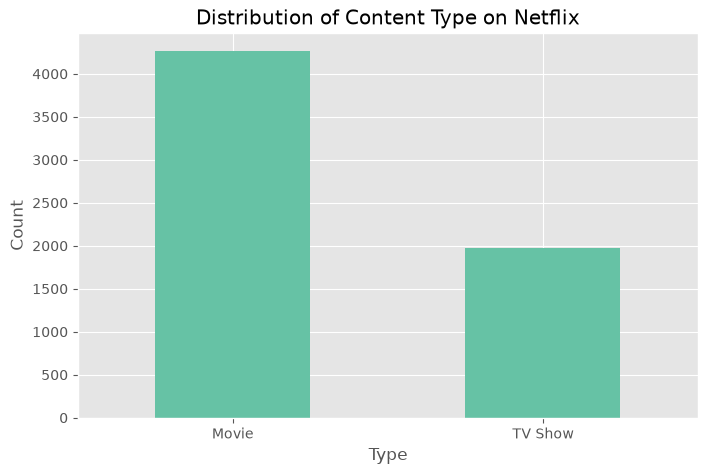

In [16]:
plt.figure(figsize=(8,5))
df['type'].value_counts().plot(kind='bar')
plt.title('Distribution of Content Type on Netflix')
plt.xlabel('Type')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

## 2. Content by Country

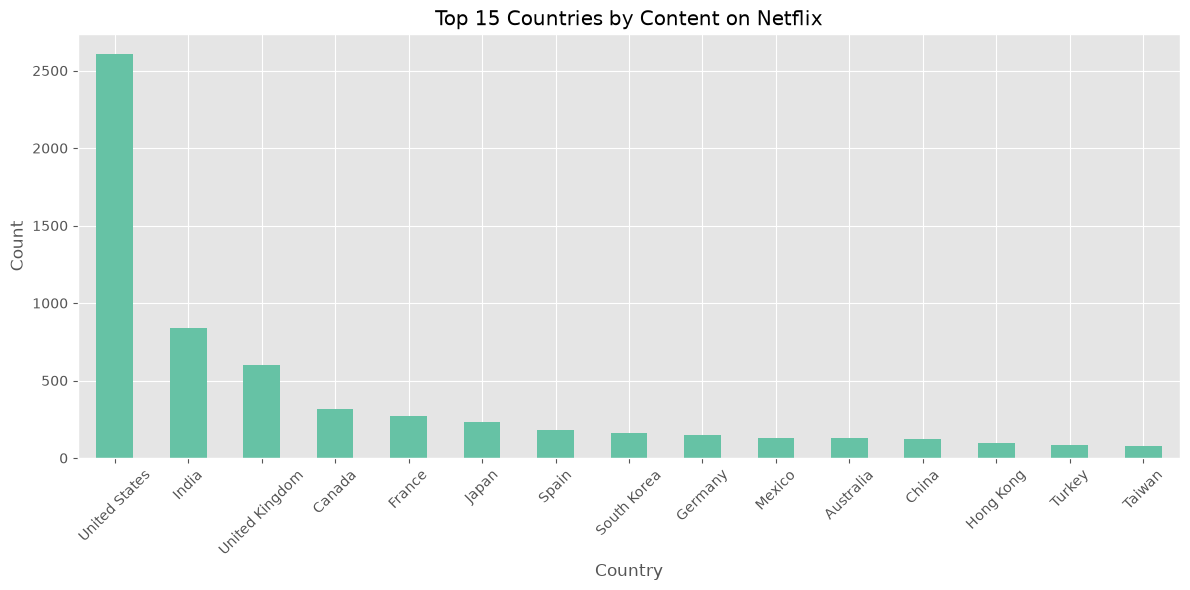

In [17]:
# Split countries (some have multiple)
country_df = df.copy()
country_df['country'] = country_df['country'].str.split(', ')
country_df = country_df.explode('country')
country_df = country_df[country_df['country'] != 'Unknown']

top_countries = country_df['country'].value_counts().head(15)
plt.figure(figsize=(12,6))
top_countries.plot(kind='bar')
plt.title('Top 15 Countries by Content on Netflix')
plt.xlabel('Country')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

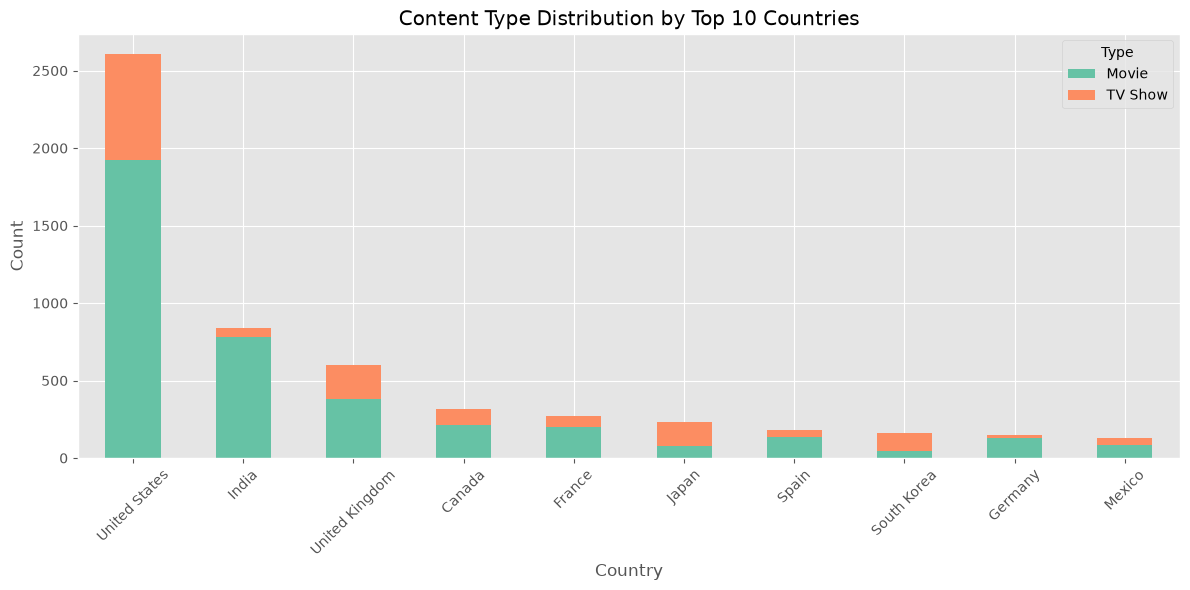

In [25]:
# 1. Get the true top 10 countries sorted by count in descending order
top10 = country_df['country'].value_counts().head(10).index

# 2. Filter the DataFrame for these top countries
df_filtered = country_df[country_df['country'].isin(top10)].copy()
df_filtered['country'] = df_filtered['country'].astype(str)

# 3. Create the crosstab
ct = pd.crosstab(df_filtered['country'], df_filtered['type'])

# 4. Explicitly reindex the crosstab to match the descending order of top10
ct = ct.reindex(top10)

# 5. Plot the sorted, stacked bar chart
ct.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Content Type Distribution by Top 10 Countries')
plt.xlabel('Country')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Type')
plt.tight_layout()
plt.show()

## 3. Has Netflix been increasingly focusing on TV rather than movies in recent years?

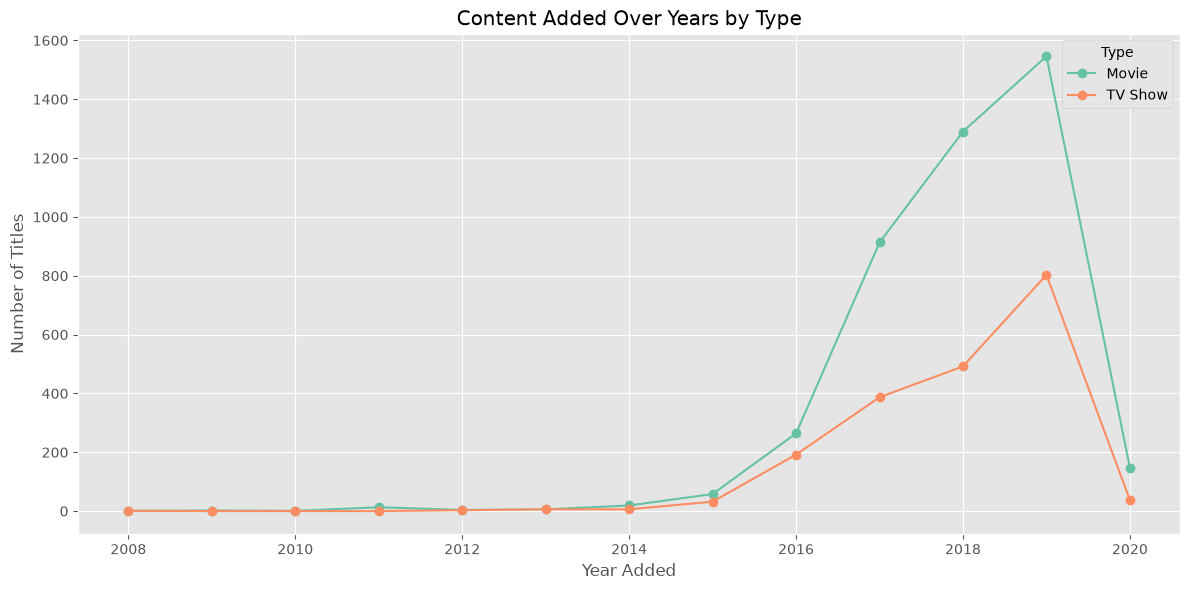

In [19]:
# Analyze by year added
year_type = df[df['year_added'].notna()].groupby(['year_added', 'type']).size().unstack(fill_value=0)
year_type.plot(kind='line', figsize=(12,6), marker='o')
plt.title('Content Added Over Years by Type')
plt.xlabel('Year Added')
plt.ylabel('Number of Titles')
plt.legend(title='Type')
plt.grid(True)
plt.tight_layout()
plt.show()

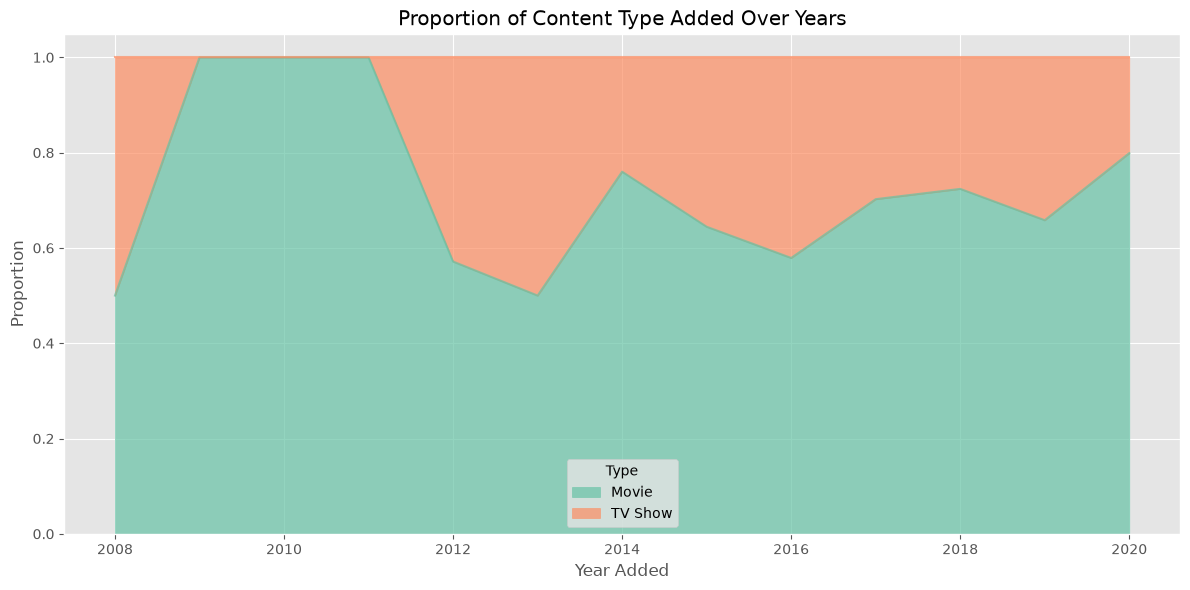

type,Movie,TV Show
year_added,,
2008.0,0.500000,0.500000
2009.0,1.000000,0.000000
2010.0,1.000000,0.000000
2011.0,1.000000,0.000000
2012.0,0.571429,0.428571
2013.0,0.500000,0.500000
2014.0,0.760000,0.240000
2015.0,0.644444,0.355556
2016.0,0.578947,0.421053


In [20]:
# Proportion over years
year_type_prop = year_type.div(year_type.sum(axis=1), axis=0)
year_type_prop.plot(kind='area', stacked=True, figsize=(12,6), alpha=0.7)
plt.title('Proportion of Content Type Added Over Years')
plt.xlabel('Year Added')
plt.ylabel('Proportion')
plt.legend(title='Type')
plt.tight_layout()
plt.show()
year_type_prop

## 4. Clustering similar content by matching text-based features

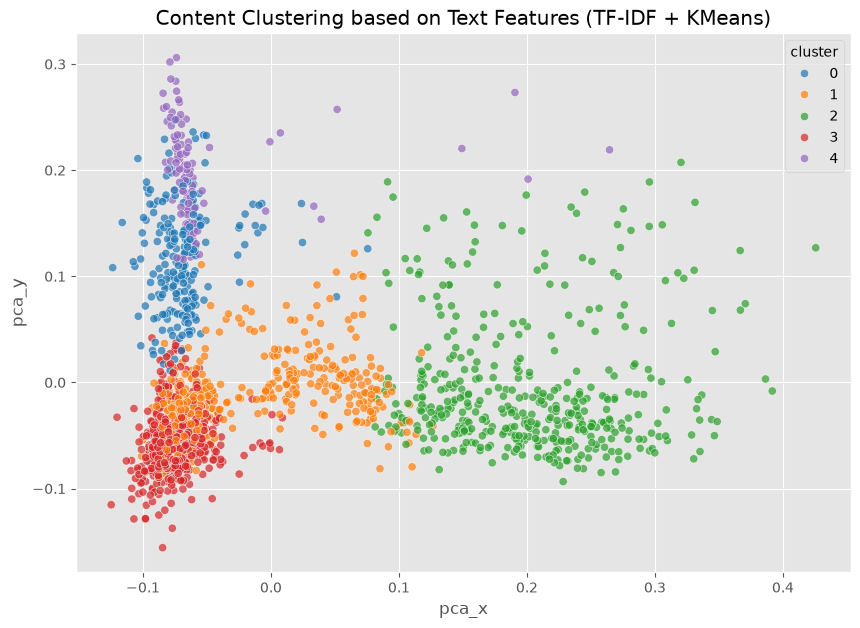

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Create text features from description, listed_in, cast
df_cluster = df.copy()
df_cluster['text_features'] = df_cluster['description'].fillna('') + ' ' + \
                               df_cluster['listed_in'].fillna('') + ' ' + \
                               df_cluster['cast'].fillna('')

# Sample for efficiency if needed
sample_size = min(2000, len(df_cluster))
df_sample = df_cluster.sample(sample_size, random_state=42)

tfidf = TfidfVectorizer(stop_words='english', max_features=5000)
tfidf_matrix = tfidf.fit_transform(df_sample['text_features'])

# KMeans clustering
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
clusters = kmeans.fit_predict(tfidf_matrix)
df_sample['cluster'] = clusters

# PCA for visualization
pca = PCA(n_components=2, random_state=42)
pca_result = pca.fit_transform(tfidf_matrix.toarray())
df_sample['pca_x'] = pca_result[:,0]
df_sample['pca_y'] = pca_result[:,1]

plt.figure(figsize=(10,7))
sns.scatterplot(data=df_sample, x='pca_x', y='pca_y', hue='cluster', palette='tab10', alpha=0.7)
plt.title('Content Clustering based on Text Features (TF-IDF + KMeans)')
plt.show()

In [22]:
# Show sample titles per cluster
for i in range(5):
    print(f'\n=== Cluster {i} ===')
    print(df_sample[df_sample['cluster']==i][['title', 'type', 'listed_in']].head(5).to_string())


=== Cluster 0 ===
                                    title     type                            listed_in
6165               QB1: Beyond the Lights  TV Show                           Docuseries
1056  Guatemala: Heart of the Mayan World    Movie  Documentaries, International Movies
2004          Hiroshima: The Real History    Movie                        Documentaries
5153              The Truth About Alcohol    Movie  Documentaries, International Movies
3674                            Not Alone    Movie                        Documentaries

=== Cluster 1 ===
                              title     type                                listed_in
599     License to Drill: Louisiana  TV Show                               Reality TV
1188               The Longest Yard    Movie  Classic Movies, Comedies, Sports Movies
5822                       LoliRock  TV Show                                 Kids' TV
1074  Hoodwinked Too! Hood vs. Evil    Movie       Children & Family Movies, Comedies
2168

## Additional Insights

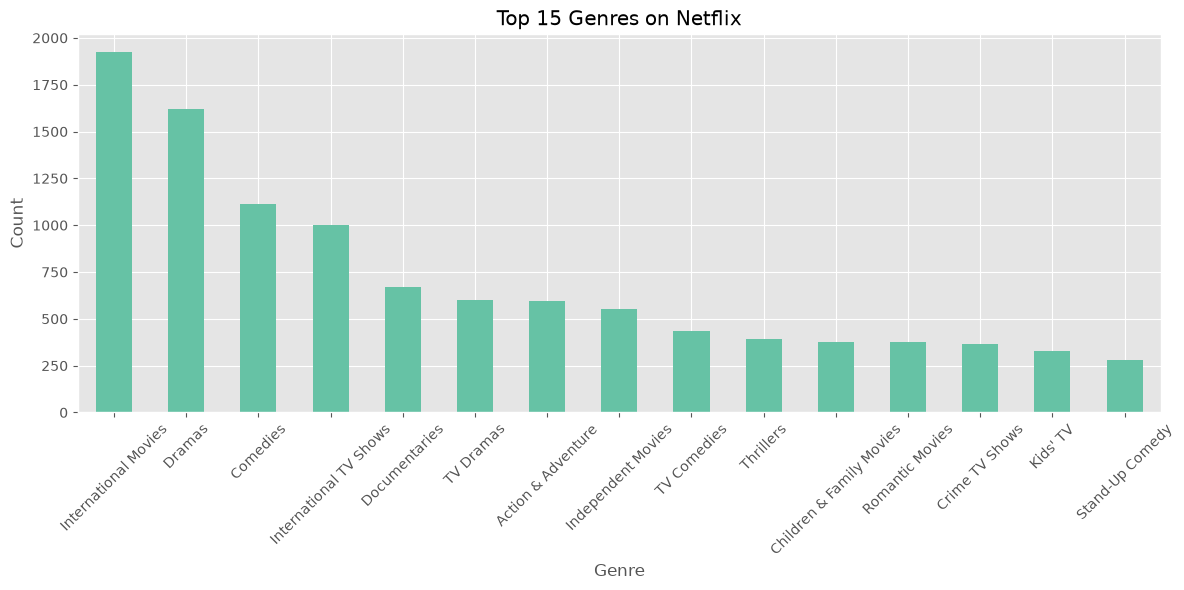

In [23]:
# Top genres
genre_df = df.copy()
genre_df['listed_in'] = genre_df['listed_in'].str.split(', ')
genre_df = genre_df.explode('listed_in')
plt.figure(figsize=(12,6))
genre_df['listed_in'].value_counts().head(15).plot(kind='bar')
plt.title('Top 15 Genres on Netflix')
plt.xlabel('Genre')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()